# Semantic Search for Hindi Documents
### Do sentence embeddings find better matches than keyword search?

**CSE413 · Speech and Natural Language Processing · Minor Project (End-Term)**
**Team:** Abhinav Marlingaplar (2023BCD0013) · Saksham Saklani (2023BCD0049)

## Problem and midterm recap

**Problem.** Given a Hindi question (the *query*), find the most similar questions in a collection of 5,046 Hindi questions (the *corpus*). This is the core of search engines, FAQ matching and duplicate-question detection.

**Two ways to do it**
- **Keyword search** (TF-IDF, BM25): finds documents that share words with the query.
- **Semantic search** (embeddings): turns each sentence into a list of numbers that captures its meaning, so sentences with the same meaning match even when the words differ.

**Midterm.** We compared TF-IDF with one embedding model (MiniLM) on 8 hand-picked queries and judged the results by eye. We computed no scores.

**This notebook** fixes that:

| Step | What we do |
|---|---|
| Check the baseline | We found that our midterm TF-IDF cut Hindi words into pieces (Section 5) |
| Measure properly | Score all 50 queries with standard metrics, and verify that our scoring code is correct |
| Add stronger methods | BM25, a larger embedding model (multilingual E5), and a keyword + embedding combination |
| Test if differences are real | Confidence intervals, because 50 queries is a small sample |
| Study the errors | Read examples where each method wins or fails |
| Try it | A small interface to search any Hindi question and to explore the 50 evaluation queries (Section 14) |

### Key terms

| Term | Meaning |
|---|---|
| **Query** | The question we search with |
| **Corpus** | The collection of questions we search in |
| **Relevant document** | A corpus question with the same meaning as the query (a duplicate). The dataset provides these labels (called *qrels*), about 1.4 per query |
| **Rank** | Position in the result list (rank 1 = top result) |
| **TF-IDF** | Scores a document higher when it shares words with the query, and gives rare words more weight |
| **BM25** | An improved TF-IDF that is used in most search engines |
| **Embedding** | A list of numbers representing the meaning of a sentence. Similar sentences get similar numbers; we compare them with cosine similarity |
| **MiniLM, mE5** | Two pre-trained embedding models that support Hindi (mE5 is the larger one) |
| **Hybrid (RRF)** | Combines two rankings: a document scores high if both methods rank it high |

The scoring metrics (nDCG, MRR, Recall) are explained in Section 6.

## 1 · Setup
Installs the libraries, fixes the random seed (so results can be repeated) and loads a Hindi font for the charts. A GPU makes the embedding step faster but is not required.

In [1]:
!pip install -q datasets sentence-transformers scikit-learn rank_bm25 ranx

In [2]:
import os, re, json, random, unicodedata, urllib.request, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)
for d in ("cache", "results"):
    os.makedirs(d, exist_ok=True)

# Devanagari font (same approach as the midterm notebook)
FONT_PATH = "NotoSansDevanagari.ttf"
FONT_URL = "https://raw.githubusercontent.com/google/fonts/main/ofl/notosansdevanagari/NotoSansDevanagari%5Bwdth%2Cwght%5D.ttf"
try:
    if not os.path.exists(FONT_PATH):
        urllib.request.urlretrieve(FONT_URL, FONT_PATH)
    fm.fontManager.addfont(FONT_PATH)
    plt.rcParams["font.family"] = fm.FontProperties(fname=FONT_PATH).get_name()
except Exception as e:
    print("Font setup failed (Hindi glyphs in plots may not render):", e)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold"})
pd.set_option("display.max_colwidth", 90)

# One colour per method family, used consistently in every chart
C_BASE, C_LEX, C_DENSE, C_HYB = "#9AA0A6", "#4C72B0", "#DD8452", "#55A868"
print("Setup complete.")

Setup complete.


## 2 · Data
We use the same dataset as the midterm, `Bharat_NanoQuoraRetrieval_hi` (Quora questions translated to Hindi): 5,046 corpus questions and 50 queries. For each query the dataset lists which corpus questions are its duplicates (70 labels in total). These labels let us compute scores.

Two checks before evaluating:
1. **Query also in the corpus.** Such a query would trivially match itself, so we would remove that match. None were found.
2. **Exact duplicates.** A few queries have a labelled-relevant document with identical text. This is allowed but makes the query easy; Section 7 checks whether it affects the results.

In [3]:
from datasets import load_dataset

REPO = "carlfeynman/Bharat_NanoQuoraRetrieval_hi"
corpus_df  = load_dataset(REPO, "corpus")["train"].to_pandas()
queries_df = load_dataset(REPO, "queries")["train"].to_pandas()
qrels_df   = load_dataset(REPO, "qrels")["train"].to_pandas()

print(f"Documents: {len(corpus_df)} | Queries: {len(queries_df)} | Qrels rows: {len(qrels_df)}")
print("Qrels columns:", qrels_df.columns.tolist())
qrels_df.head()

Documents: 5046 | Queries: 50 | Qrels rows: 70
Qrels columns: ['query-id', 'corpus-id']


,query-id,corpus-id
0,127728,127729
1,318820,318821
2,296098,296097
3,150414,192835
4,145582,145583


In [4]:
def clean_text(t):
    """Midterm preprocessing: NFC normalization + whitespace cleanup."""
    if not isinstance(t, str):
        return ""
    return re.sub(r"\s+", " ", unicodedata.normalize("NFC", t)).strip()

for df in (corpus_df, queries_df):
    df["_id"] = df["_id"].astype(str)
    df["text_clean"] = df["text"].apply(clean_text)

# --- build qrels dict {query_id: {doc_id: relevance}} (column names detected, not assumed) ---
def _find(cols, *keys):
    for c in cols:
        if any(k in c.lower() for k in keys):
            return c
    raise KeyError(f"No column matching {keys} in {list(cols)}")

qcol = _find(qrels_df.columns, "query")
dcol = _find([c for c in qrels_df.columns if c != qcol], "corpus", "doc")
scol = next((c for c in qrels_df.columns if c not in (qcol, dcol)
             and any(k in c.lower() for k in ("score", "rel", "label"))), None)
print(f"qrels columns used -> query: '{qcol}', doc: '{dcol}', score: {scol!r}")

QRELS = {}
for _, r in qrels_df.iterrows():
    gain = int(r[scol]) if scol else 1
    if gain > 0:
        QRELS.setdefault(str(r[qcol]), {})[str(r[dcol])] = gain

corpus_ids   = corpus_df["_id"].tolist()
corpus_texts = corpus_df["text_clean"].tolist()
text_by_id   = dict(zip(corpus_ids, corpus_texts))
QIDS   = [q for q in queries_df["_id"] if q in QRELS]
QTEXTS = queries_df.set_index("_id").loc[QIDS, "text_clean"].tolist()

missing = sum(1 for q in QRELS.values() for d in q if d not in text_by_id)
print(f"Evaluable queries: {len(QIDS)} | relevant docs per query (mean): "
      f"{np.mean([len(QRELS[q]) for q in QIDS]):.2f} | qrels pointing to missing docs: {missing}")

# --- self-match detection: a corpus doc whose text is identical to the query (and is not a labelled answer) ---
text2idx = {}
for i, t in enumerate(corpus_texts):
    text2idx.setdefault(t, []).append(i)

SELF_EXCL = {qid: [i for i in text2idx.get(qt, []) if corpus_ids[i] not in QRELS[qid]]
             for qid, qt in zip(QIDS, QTEXTS)}
n_self = sum(1 for v in SELF_EXCL.values() if v)
print(f"Queries that also appear verbatim in the corpus as unlabelled docs (excluded from rankings): {n_self}/{len(QIDS)}")

# A different phenomenon: the query's *labelled-relevant* doc may be textually identical to the query (an exact duplicate).
# That is legitimate, not a self-match, but it makes the query trivial for every method.
DUPS = {qid: [d for d in QRELS[qid] if text_by_id[d] == qt] for qid, qt in zip(QIDS, QTEXTS)}
DUP_QIDS = [q for q, v in DUPS.items() if v]
print(f"Queries whose labelled-relevant document is textually identical to the query: {len(DUP_QIDS)}/{len(QIDS)}")

qrels columns used -> query: 'query-id', doc: 'corpus-id', score: None
Evaluable queries: 50 | relevant docs per query (mean): 1.40 | qrels pointing to missing docs: 0
Queries that also appear verbatim in the corpus as unlabelled docs (excluded from rankings): 0/50
Queries whose labelled-relevant document is textually identical to the query: 3/50


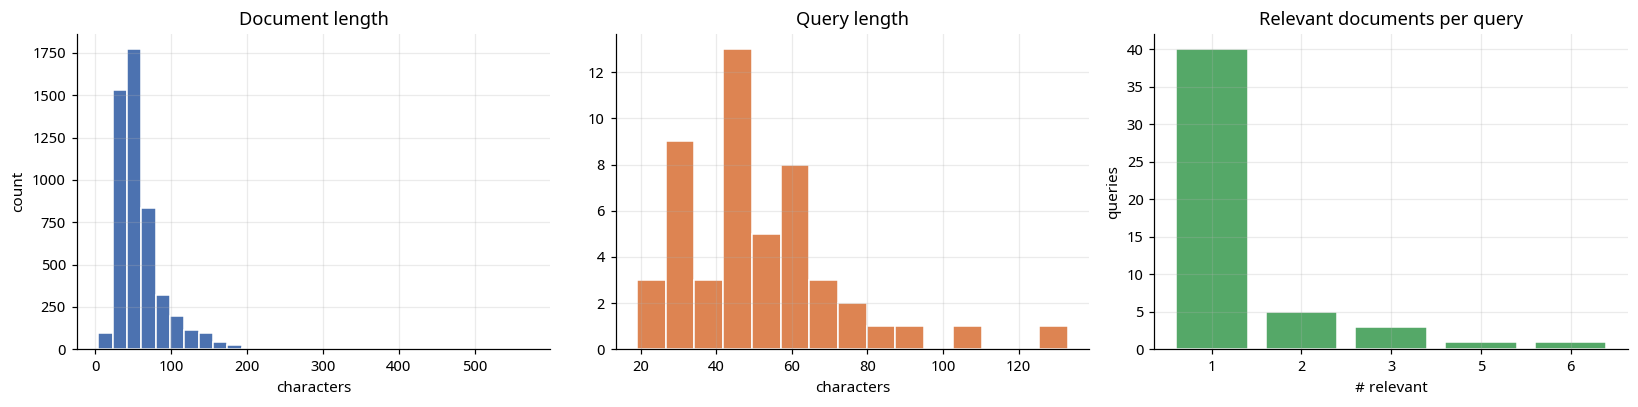

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(corpus_df["text_clean"].str.len(), bins=30, color=C_LEX, edgecolor="white")
ax[0].set_title("Document length"); ax[0].set_xlabel("characters"); ax[0].set_ylabel("count")
ax[1].hist(queries_df["text_clean"].str.len(), bins=15, color=C_DENSE, edgecolor="white")
ax[1].set_title("Query length"); ax[1].set_xlabel("characters")
rel_counts = pd.Series([len(QRELS[q]) for q in QIDS]).value_counts().sort_index()
ax[2].bar(rel_counts.index.astype(str), rel_counts.values, color=C_HYB, edgecolor="white")
ax[2].set_title("Relevant documents per query"); ax[2].set_xlabel("# relevant"); ax[2].set_ylabel("queries")
plt.tight_layout(); plt.savefig("results/fig_data_overview.png", dpi=150, bbox_inches="tight"); plt.show()

## 3 · The retrieval methods
Each method takes a query and gives a score to every corpus question; the highest scores are the top results. We use one function for all methods so the comparison is fair.

| Method | How it works | Why it is here |
|---|---|---|
| TF-IDF (midterm) | scikit-learn default settings | Our midterm baseline |
| TF-IDF (fixed) | Same, with a tokenizer that keeps Hindi words whole | Corrected baseline |
| BM25 | Keyword scoring used in most search engines | Standard keyword baseline |
| MiniLM | Embedding model `paraphrase-multilingual-MiniLM-L12-v2` | Our midterm embedding model |
| mE5-base | Larger embedding model `multilingual-e5-base` (it expects "query:" and "passage:" before the text) | Stronger embedding model |
| Hybrid (RRF) | Each method gives a document 1 / (60 + rank); the two values are added | Tests whether combining helps |

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer
import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

# Keep everything that is not whitespace/punctuation as part of a word -> matras and conjuncts stay attached
TOKEN_PATTERN = r"[^\s\?\.,!।:;\"'()]+"
tok = lambda s: re.findall(TOKEN_PATTERN, s.lower())

# ---------- lexical models ----------
VEC = {
    "tfidf_mid":  TfidfVectorizer(),                                              # midterm baseline (defaults)
    "tfidf":      TfidfVectorizer(token_pattern=TOKEN_PATTERN),                   # fixed tokenizer
}
MAT = {k: v.fit_transform(corpus_texts) for k, v in VEC.items()}
bm25 = BM25Okapi([tok(t) for t in corpus_texts])

# ---------- dense models (document embeddings cached to disk) ----------
DENSE = {
    "minilm": dict(name="paraphrase-multilingual-MiniLM-L12-v2", qp="",        dp=""),
    "e5":     dict(name="intfloat/multilingual-e5-base",        qp="query: ", dp="passage: "),
}
MODELS, DOCEMB = {}, {}
for key, cfg in DENSE.items():
    MODELS[key] = SentenceTransformer(cfg["name"], device=DEVICE)
    path = f"cache/{key}_docs.npy"
    if os.path.exists(path):
        DOCEMB[key] = np.load(path)
    else:
        DOCEMB[key] = MODELS[key].encode([cfg["dp"] + t for t in corpus_texts], batch_size=64,
                                         normalize_embeddings=True, show_progress_bar=True)
        np.save(path, DOCEMB[key])
    print(f"{key:7s} doc embeddings: {DOCEMB[key].shape}")

N_DOCS, RRF_K = len(corpus_texts), 60
HYBRID_COMPONENTS = ["bm25", "e5"]       # re-set after the dense models are evaluated (Section 6)

# ---------- unified scoring ----------
def _rank_vec(s):
    """Rank of every document (1 = best) for a score vector."""
    order = np.argsort(-s, kind="stable")
    r = np.empty(len(s), dtype=int); r[order] = np.arange(1, len(s) + 1)
    return r

def base_scores(query, method):
    q = clean_text(query)
    if method in VEC:
        return (VEC[method].transform([q]) @ MAT[method].T).toarray().ravel()
    if method == "bm25":
        return np.asarray(bm25.get_scores(tok(q)), dtype=float)
    if method in DENSE:
        e = MODELS[method].encode([DENSE[method]["qp"] + q], normalize_embeddings=True, show_progress_bar=False)[0]
        return DOCEMB[method] @ e
    raise ValueError(f"unknown method {method}")

def score_vector(query, method, exclude=()):
    """Score of every corpus document for `query`. `exclude` = doc indices forced to -inf (self-matches)."""
    exclude = list(exclude)
    if method == "hybrid":
        s = np.zeros(N_DOCS)
        for comp in HYBRID_COMPONENTS:
            b = base_scores(query, comp).astype(float)
            if exclude: b[exclude] = -np.inf
            s += 1.0 / (RRF_K + _rank_vec(b))
    else:
        s = base_scores(query, method).astype(float)
    if exclude: s[exclude] = -np.inf
    return s

def search(query, method="hybrid", k=5, exclude=()):
    s = score_vector(query, method, exclude)
    top = np.argsort(-s, kind="stable")[:k]
    return [(corpus_ids[i], corpus_texts[i], float(s[i])) for i in top]

print("Engine ready. Vocabulary sizes ->",
      {k: len(v.vocabulary_) for k, v in VEC.items()})

Device: cuda


minilm  doc embeddings: (5046, 384)


e5      doc embeddings: (5046, 768)
Engine ready. Vocabulary sizes -> {'tfidf_mid': 1556, 'tfidf': 6172}


## 4 · Midterm results, reproduced
Same 8 queries and same two methods as the midterm (default TF-IDF and MiniLM). The last two columns show whether the top result has exactly the same text as the query. This happens for Q7; the next cell explains why.

In [7]:
representative_queries = {
    "Q1 (definition)":          "स्क्रम मास्टर क्या है?",
    "Q2 (definition)":          "डेटाबेस प्रबंधन प्रणाली का उद्देश्य क्या है?",
    "Q3 (numeric/entity)":      "पेप्सीको इंक का आईपीओ मूल्य क्या था? 100 शेयर आज कितने मूल्य के होंगे?",
    "Q4 (opinion)":             "एक IITian होना कैसा होता है?",
    "Q5 (advice/emotional)":    "मैं अपराधबोध से कैसे उबर सकता हूँ?",
    "Q6 (paraphrase test)":     "मैं मनोचिकित्सक की मदद के बिना अवसाद को कैसे दूर कर सकता हूँ?",
    "Q7 (opinion/geopolitical)":"उत्तर कोरिया संयुक्त राज्य अमेरिका से नफरत क्यों करता है?",
    "Q8 (abstract)":            "समय इतनी तेजी से क्यों गुजरता है जब आप वास्तव में अपने जीवन के साथ कुछ कर रहे हैं?",
}
rows = []
for label, q in representative_queries.items():
    t, s = search(q, "tfidf_mid", 1)[0], search(q, "minilm", 1)[0]
    rows.append({"Query": label, "TF-IDF top-1": t[1], "MiniLM top-1": s[1],
                 "TF-IDF top-1 = query text": t[1] == clean_text(q), "MiniLM top-1 = query text": s[1] == clean_text(q)})
pd.DataFrame(rows)

,Query,TF-IDF top-1,MiniLM top-1,TF-IDF top-1 = query text,MiniLM top-1 = query text
0,Q1 (definition),स्क्रम मास्टर की भूमिकाएं और जिम्मेदारियां क्या हैं?,मास्टर.जीजी क्या है?,False,False
1,Q2 (definition),डेटाबेस प्रबंधन प्रणाली का मुख्य कार्य क्या है?,डेटाबेस प्रबंधन प्रणाली का मुख्य कार्य क्या है?,False,False
2,Q3 (numeric/entity),सिमेंटेक का आईपीओ मूल्य क्या था? 100 शेयर आज कितने मूल्य के होंगे?,कॉमकास्ट का आईपीओ मूल्य क्या था? 100 शेयर आज कितने मूल्य के होंगे?,False,False
3,Q4 (opinion),एक IITian होने का कैसा महसूस होता है?,एक IITian होने का कैसा महसूस होता है?,False,False
4,Q5 (advice/emotional),मैं अपराधबोध को कैसे दूर कर सकता हूँ?,मैं अपराधबोध को कैसे दूर कर सकता हूँ?,False,False
5,Q6 (paraphrase test),मैं पेशेवर मदद के बिना अवसाद को कैसे दूर कर सकता हूँ?,मैं मनोचिकित्सकों के पास जाने के बिना अवसाद से कैसे बच सकता हूँ?,False,False
6,Q7 (opinion/geopolitical),उत्तर कोरिया संयुक्त राज्य अमेरिका से नफरत क्यों करता है?,उत्तर कोरिया संयुक्त राज्य अमेरिका से नफरत क्यों करता है?,True,True
7,Q8 (abstract),समय हर साल तेजी से गुजरता है। वहाँ एक तरीका है कि मैं इसे फिर से धीमा कर सकते हैं?,समय इतनी जल्दी क्यों बीतता है?,False,False


In [8]:
# Is an "identical top-1" a self-match, or an exact-duplicate relevant document?
qt2qid = dict(zip(QTEXTS, QIDS))
for label, q in representative_queries.items():
    qid = qt2qid.get(clean_text(q))
    if qid is not None and any(r_["TF-IDF top-1 = query text"] or r_["MiniLM top-1 = query text"] for r_ in rows if r_["Query"] == label):
        print(f"{label}: query id {qid} | labelled-relevant doc is an exact duplicate of the query: {bool(DUPS[qid])}")

Q7 (opinion/geopolitical): query id 26645 | labelled-relevant doc is an exact duplicate of the query: True


## 5 · Checking the midterm TF-IDF baseline
**Problem.** *Tokenization* means splitting text into words. scikit-learn's default splitter does not treat Hindi vowel signs (matras) and the joining mark (virama) as part of a word, so it cuts Hindi words into fragments. For example, "स्क्रम मास्टर" became ['रम', 'टर']. This is why our midterm vocabulary had only 1,556 terms.

**Fix.** Split only on spaces and punctuation.

**Result.** The midterm tokenizer kept 0% of the words that contain a vowel sign or virama intact, and such words are 90% of the corpus. After the fix the vocabulary has 6,172 terms. Whether this improves *ranking quality* is tested in Section 9.

,query,midterm tokens,fixed tokens
0,स्क्रम मास्टर क्या है?,"[रम, टर]","[स्क्रम, मास्टर, क्या, है]"
1,डेटाबेस प्रबंधन प्रणाली का उद्देश्य क्या है?,"[रब, धन, रण, उद]","[डेटाबेस, प्रबंधन, प्रणाली, का, उद्देश्य, क्या, है]"
2,मैं अपराधबोध से कैसे उबर सकता हूँ?,"[अपर, धब, उबर, सकत]","[मैं, अपराधबोध, से, कैसे, उबर, सकता, हूँ]"


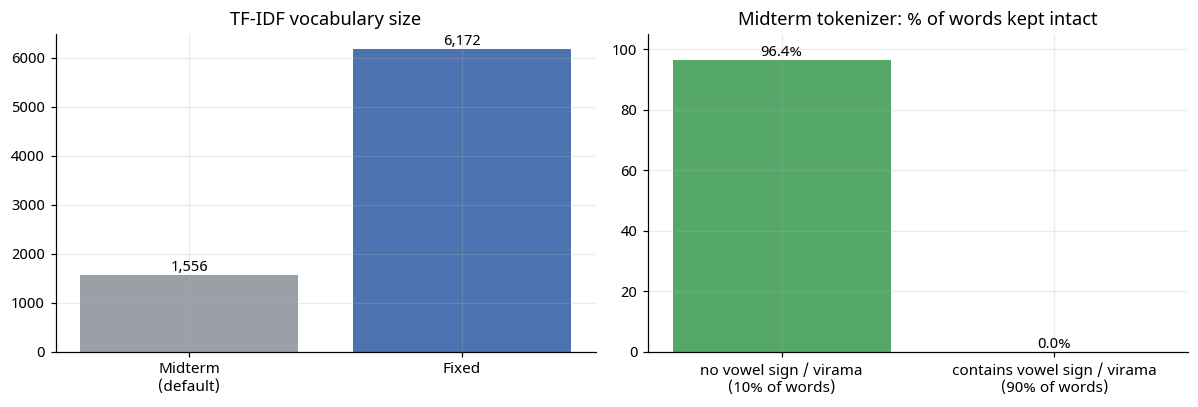

In [9]:
demo = [representative_queries[k] for k in ("Q1 (definition)", "Q2 (definition)", "Q5 (advice/emotional)")]
display(pd.DataFrame({"query": demo,
                      "midterm tokens": [VEC["tfidf_mid"].build_analyzer()(q) for q in demo],
                      "fixed tokens":   [VEC["tfidf"].build_analyzer()(q) for q in demo]}))

# Independent check: does the midterm tokenizer return a word unchanged as a single token?
mid_an = VEC["tfidf_mid"].build_analyzer()
has_mark = lambda w: any(unicodedata.category(ch) in ("Mn", "Mc") for ch in w)
words = [w for t in corpus_texts for w in tok(t)]
grp = {"no vowel sign / virama": [w for w in words if not has_mark(w)],
       "contains vowel sign / virama": [w for w in words if has_mark(w)]}
survive = {g: np.mean([mid_an(w) == [w] for w in ws]) * 100 for g, ws in grp.items()}
share   = {g: len(ws) / len(words) * 100 for g, ws in grp.items()}

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(["Midterm\n(default)", "Fixed"], [len(VEC["tfidf_mid"].vocabulary_), len(VEC["tfidf"].vocabulary_)], color=[C_BASE, C_LEX])
ax[0].set_title("TF-IDF vocabulary size")
for i, v in enumerate([len(VEC["tfidf_mid"].vocabulary_), len(VEC["tfidf"].vocabulary_)]):
    ax[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontweight="bold")
labels = [f"{g}\n({share[g]:.0f}% of words)" for g in grp]
ax[1].bar(labels, list(survive.values()), color=[C_HYB, C_BASE])
ax[1].set_title("Midterm tokenizer: % of words kept intact"); ax[1].set_ylim(0, 105)
for i, v in enumerate(survive.values()):
    ax[1].text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontweight="bold")
plt.tight_layout(); plt.savefig("results/fig_tokenizer_audit.png", dpi=150, bbox_inches="tight"); plt.show()

## 6 · Measuring performance
For each query we have a ranked list from a method and the labelled relevant documents. We use three standard scores, each between 0 and 1 (higher is better), computed on the top 10 results:

| Metric | Question it answers | Example (one relevant document) |
|---|---|---|
| **Recall@10** | Is the relevant document in the top 10? | Yes → 1, no → 0 |
| **MRR@10** | How high is the first relevant document? | Rank 1 → 1.0, rank 2 → 0.5, rank 4 → 0.25 |
| **nDCG@10** | Like MRR, but also rewards placing *all* relevant documents high. **Our main metric**; it is also the main metric of the BEIR and Hindi-BEIR papers | Rank 1 → 1.0, rank 2 → 0.63, rank 3 → 0.5 |

We omit Precision and Recall@100: each query has only about 1.4 relevant documents, so they add no information.

**Is our code correct?** We wrote the metrics ourselves, then checked them: a perfect ranking scores 1.0, a ranking with no relevant document scores 0, and our numbers match the `ranx` library to 6 decimal places.

In [10]:
def _dcg(gains):
    return sum(g / np.log2(i + 2) for i, g in enumerate(gains))

def ndcg_at_k(ranked, rel, k=10):
    idcg = _dcg(sorted(rel.values(), reverse=True)[:k])
    return _dcg([rel.get(d, 0) for d in ranked[:k]]) / idcg if idcg > 0 else 0.0

def mrr_at_k(ranked, rel, k=10):
    for i, d in enumerate(ranked[:k]):
        if d in rel: return 1.0 / (i + 1)
    return 0.0

def recall_at_k(ranked, rel, k):
    return sum(d in rel for d in ranked[:k]) / len(rel)

def per_query_metrics(rankings):
    """rankings: {qid: [doc_id, ...] best-first}  ->  DataFrame indexed by qid"""
    rows = {}
    for q in QIDS:
        r, rel = rankings[q], QRELS[q]
        rows[q] = {"ndcg@10": ndcg_at_k(r, rel, 10), "mrr@10": mrr_at_k(r, rel, 10),
                   "recall@10": recall_at_k(r, rel, 10)}
    return pd.DataFrame.from_dict(rows, orient="index")

def run_method(method, topk=100):
    """Rank the whole corpus for every query (self-matches excluded) and keep the top-k doc ids."""
    out = {}
    for qid, qt in zip(QIDS, QTEXTS):
        s = score_vector(qt, method, exclude=SELF_EXCL[qid])
        out[qid] = [corpus_ids[i] for i in np.argsort(-s, kind="stable")[:topk]]
    return out

# ---------- sanity checks on the harness ----------
perfect = {q: list(QRELS[q]) + [d for d in corpus_ids if d not in QRELS[q]][:99] for q in QIDS}
worst   = {q: [d for d in corpus_ids if d not in QRELS[q]][:100] for q in QIDS}
print("perfect ranking ->", per_query_metrics(perfect).mean().round(3).to_dict())
print("no-hit ranking  ->", per_query_metrics(worst).mean().round(3).to_dict())

# ---------- cross-check against ranx ----------
from ranx import Qrels, Run, evaluate
check_run = run_method("tfidf")
ranx_res = evaluate(Qrels.from_dict({q: QRELS[q] for q in QIDS}),
                    Run.from_dict({q: {d: float(len(l) - i) for i, d in enumerate(l)} for q, l in check_run.items()}),
                    ["ndcg@10", "mrr@10", "recall@10"])
mine = per_query_metrics(check_run).mean()
for m in ("ndcg@10", "mrr@10", "recall@10"):
    ok = np.isclose(mine[m], ranx_res[m], atol=1e-6)
    print(f"{m:10s} ours={mine[m]:.6f}  ranx={ranx_res[m]:.6f}  {'MATCH' if ok else 'MISMATCH'}")

perfect ranking -> {'ndcg@10': 1.0, 'mrr@10': 1.0, 'recall@10': 1.0}
no-hit ranking  -> {'ndcg@10': 0.0, 'mrr@10': 0.0, 'recall@10': 0.0}
ndcg@10    ours=0.691867  ranx=0.691867  MATCH
mrr@10     ours=0.676333  ranx=0.676333  MATCH
recall@10  ours=0.816000  ranx=0.816000  MATCH


### Running all methods
Each method ranks all 5,046 questions for each of the 50 queries. The hybrid combines BM25 with whichever embedding model scored better (mE5-base). We choose it using the same 50 queries; this can only favour the hybrid, so it does not weaken our conclusion that the hybrid does not help.

In [11]:
NAMES = {  # display name -> engine key
    "TF-IDF (midterm)": "tfidf_mid",
    "TF-IDF (fixed)":   "tfidf",
    "BM25":             "bm25",
    "MiniLM":           "minilm",
    "mE5-base":         "e5",
    "Hybrid RRF":       "hybrid",
}
FAMILY = {"TF-IDF (midterm)": "base", "TF-IDF (fixed)": "lex", "BM25": "lex",
          "MiniLM": "dense", "mE5-base": "dense", "Hybrid RRF": "hyb"}
FAM_COLOR = {"base": C_BASE, "lex": C_LEX, "dense": C_DENSE, "hyb": C_HYB}

RANKINGS, PQ = {}, {}
def evaluate_name(name):
    RANKINGS[name] = run_method(NAMES[name])
    PQ[name] = per_query_metrics(RANKINGS[name])

for name in NAMES:
    if name == "Hybrid RRF":
        continue
    evaluate_name(name)
    print(f"{name:20s} nDCG@10 = {PQ[name]['ndcg@10'].mean():.4f}")

# choose the stronger encoder for the hybrid, then evaluate it
DENSE_BEST = max(("MiniLM", "mE5-base"), key=lambda n: PQ[n]["ndcg@10"].mean())
HYBRID_COMPONENTS = ["bm25", NAMES[DENSE_BEST]]
evaluate_name("Hybrid RRF")
print(f"{'Hybrid RRF':20s} nDCG@10 = {PQ['Hybrid RRF']['ndcg@10'].mean():.4f}   (BM25 + {DENSE_BEST})")

TF-IDF (midterm)     nDCG@10 = 0.6489
TF-IDF (fixed)       nDCG@10 = 0.6919
BM25                 nDCG@10 = 0.6583
MiniLM               nDCG@10 = 0.8452
mE5-base             nDCG@10 = 0.8930
Hybrid RRF           nDCG@10 = 0.7749   (BM25 + mE5-base)


## 7 · Results
Mean score over the 50 queries. Because 50 is a small sample, we also give a **95% confidence interval** for nDCG@10: the range in which the true score is likely to lie. We obtain it by **bootstrap**: resample the 50 queries 2,000 times and recompute the mean each time. If two intervals overlap a lot, we should not claim a difference.

In [12]:
B = 2000
def bootstrap_ci(x, B=B, seed=SEED):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(x), (B, len(x)))
    return np.percentile(x[idx].mean(axis=1), [2.5, 97.5])

rows = []
for name in NAMES:
    lo, hi = bootstrap_ci(PQ[name]["ndcg@10"].values)
    m = PQ[name].mean()
    rows.append({"Method": name, "nDCG@10": m["ndcg@10"], "95% CI low": lo, "95% CI high": hi,
                 "MRR@10": m["mrr@10"], "Recall@10": m["recall@10"]})
summary = pd.DataFrame(rows).set_index("Method")
summary.round(4).to_csv("results/summary.csv")

(summary.style
        .format("{:.3f}")
        .set_caption("Retrieval performance on Bharat-NanoQuoraRetrieval-hi (50 queries)"))

,nDCG@10,95% CI low,95% CI high,MRR@10,Recall@10
Method,,,,,
TF-IDF (midterm),0.649,0.547,0.751,0.619,0.816
TF-IDF (fixed),0.692,0.585,0.790,0.676,0.816
BM25,0.658,0.548,0.763,0.649,0.773
MiniLM,0.845,0.765,0.913,0.826,0.953
mE5-base,0.893,0.826,0.949,0.877,0.977
Hybrid RRF,0.775,0.678,0.859,0.747,0.903


**Check: do easy queries distort the results?** Three queries have a relevant document identical to the query. The table repeats nDCG@10 with and without them.

In [13]:
non_dup = [q for q in QIDS if q not in set(DUP_QIDS)]
sens = pd.DataFrame({
    "all queries":         {n: PQ[n].loc[QIDS, "ndcg@10"].mean() for n in NAMES},
    "excl. exact-duplicate queries": {n: PQ[n].loc[non_dup, "ndcg@10"].mean() for n in NAMES},
})
print(f"Queries: {len(QIDS)} total | {len(DUP_QIDS)} with an exact-duplicate relevant doc | {len(non_dup)} remaining")
sens.style.format("{:.3f}").set_caption("Mean nDCG@10: all queries vs. excluding trivial duplicates")

Queries: 50 total | 3 with an exact-duplicate relevant doc | 47 remaining


,all queries,excl. exact-duplicate queries
TF-IDF (midterm),0.649,0.633
TF-IDF (fixed),0.692,0.675
BM25,0.658,0.643
MiniLM,0.845,0.835
mE5-base,0.893,0.886
Hybrid RRF,0.775,0.761


### Observation 1 — Main results
- **mE5-base is best on all three metrics:** nDCG@10 0.893, MRR@10 0.877, Recall@10 0.977. MiniLM is second (nDCG@10 0.845).
- **Both embedding models beat every keyword method.** The best keyword method is TF-IDF (fixed) at 0.692; BM25 scores 0.658.
- **BM25 does not beat TF-IDF here** (the difference is not significant, Section 9). This is unexpected, since BM25 is usually the stronger one. A possible reason is that our queries are very short, but we did not test this.
- **The hybrid (0.775) lies between** the keyword and embedding methods instead of beating both.
- **The 3 easy queries do not matter:** removing them leaves the order of methods unchanged.
- The confidence intervals of mE5 and MiniLM overlap, so we cannot yet say mE5 is better than MiniLM.

## 8 · Charts
- **Bar chart (left):** nDCG@10 per method; the black line is the 95% confidence interval.
- **Line chart (right):** Recall@K, the fraction of relevant documents found in the top K results.
- **Heatmap:** one row per query and one column per method; darker means a better score.
- **Scatter plot:** one dot per query; a dot above the diagonal means the embedding model did better than BM25 on that query.

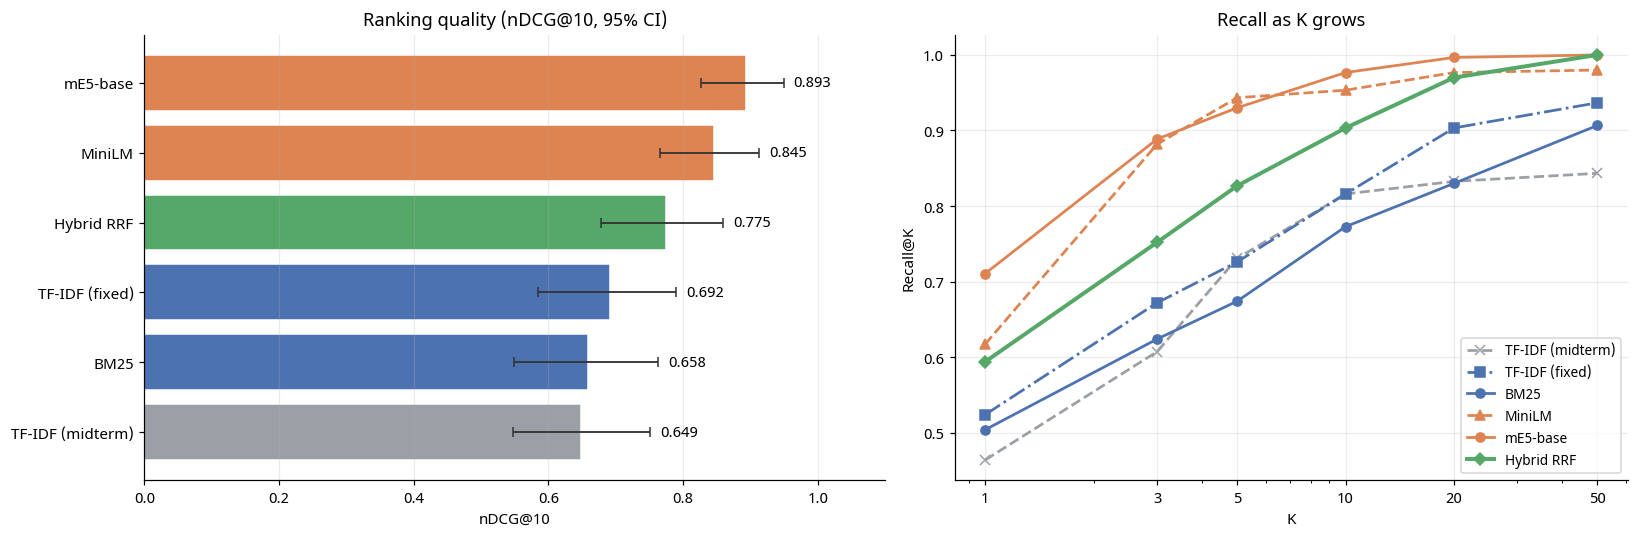

In [14]:
order = summary.sort_values("nDCG@10").index.tolist()
KS = [1, 3, 5, 10, 20, 50]
STYLE = {  # (colour, linestyle, marker) — every method distinguishable without relying on colour alone
    "TF-IDF (midterm)": (C_BASE,  "--", "x"),
    "TF-IDF (fixed)":   (C_LEX,   "-.", "s"),
    "BM25":             (C_LEX,   "-",  "o"),
    "MiniLM":           (C_DENSE, "--", "^"),
    "mE5-base":         (C_DENSE, "-",  "o"),
    "Hybrid RRF":       (C_HYB,   "-",  "D"),
}

fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.1, 1]})
vals = summary.loc[order, "nDCG@10"].values
hi = summary.loc[order, "95% CI high"].values
err = np.vstack([vals - summary.loc[order, "95% CI low"].values, hi - vals])
ax[0].barh(order, vals, xerr=err, color=[FAM_COLOR[FAMILY[n]] for n in order], edgecolor="white",
           error_kw=dict(ecolor="#333", capsize=3, lw=1.2))
for i, (v, h) in enumerate(zip(vals, hi)):
    ax[0].text(h + 0.015, i, f"{v:.3f}", va="center", fontsize=10, fontweight="bold")   # label sits right of the CI cap
ax[0].set_xlim(0, 1.1); ax[0].set_xlabel("nDCG@10")
ax[0].set_title("Ranking quality (nDCG@10, 95% CI)"); ax[0].grid(axis="y", alpha=0)

for name in NAMES:
    col, ls, mk = STYLE[name]
    curve = [np.mean([recall_at_k(RANKINGS[name][q], QRELS[q], k) for q in QIDS]) for k in KS]
    ax[1].plot(KS, curve, marker=mk, ls=ls, color=col, lw=2.6 if name == "Hybrid RRF" else 1.8, label=name, ms=6)
ax[1].set_xscale("log"); ax[1].set_xticks(KS); ax[1].set_xticklabels(KS)
ax[1].set_xlabel("K"); ax[1].set_ylabel("Recall@K"); ax[1].set_title("Recall as K grows"); ax[1].legend(fontsize=9, loc="lower right")
plt.tight_layout(); plt.savefig("results/fig_main_results.png", dpi=150, bbox_inches="tight"); plt.show()

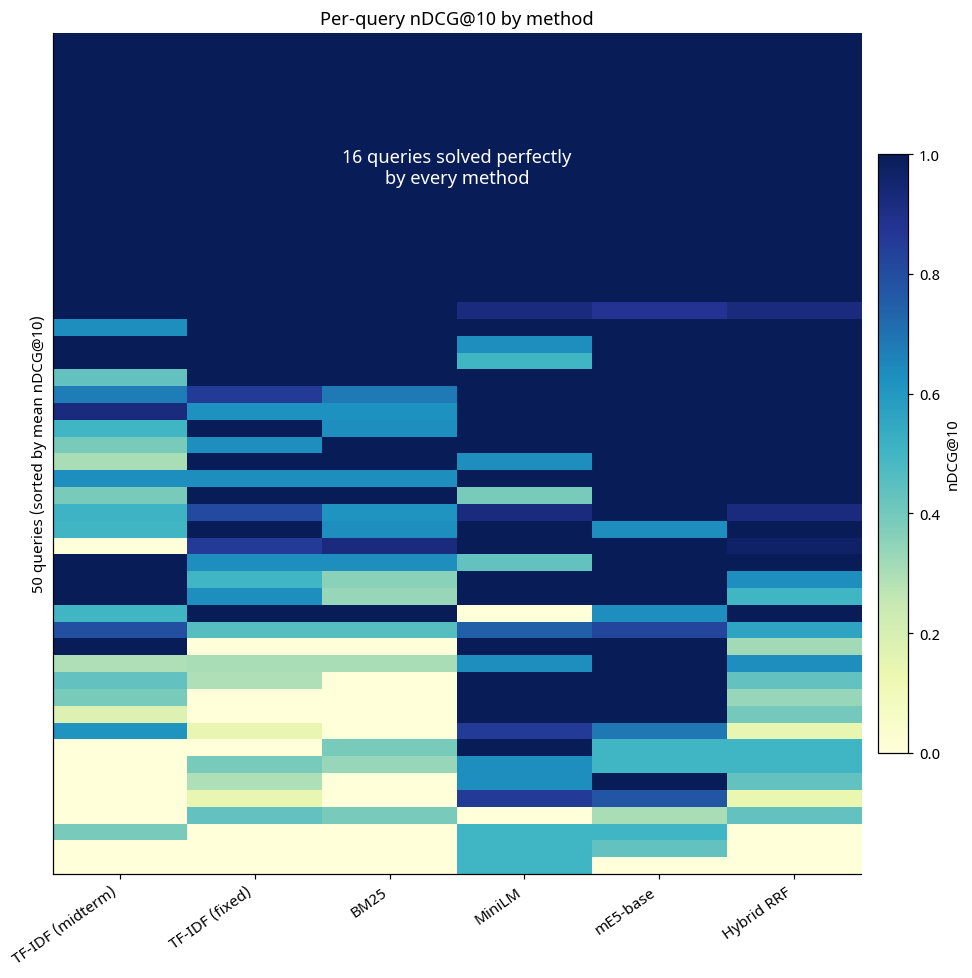

16/50 queries are solved perfectly (nDCG@10 = 1.0) by all 6 methods.


In [15]:
# Per-query nDCG@10 heatmap: do methods fail on the same queries?
M = pd.DataFrame({n: PQ[n]["ndcg@10"] for n in NAMES})
M = M.loc[M.mean(axis=1).sort_values(ascending=False, kind="stable").index]
n_all_solved = int((M.min(axis=1) >= 0.999).sum())

fig, ax = plt.subplots(figsize=(9, 9))
im = ax.imshow(M.values, aspect="auto", cmap="YlGnBu", vmin=0, vmax=1)
ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, rotation=35, ha="right")
ax.set_yticks([]); ax.set_ylabel(f"{len(M)} queries (sorted by mean nDCG@10)")
ax.text((M.shape[1] - 1) / 2, (n_all_solved - 1) / 2, f"{n_all_solved} queries solved perfectly\nby every method",
        color="white", ha="center", va="center", fontsize=12, fontweight="bold")
ax.set_title("Per-query nDCG@10 by method"); ax.grid(False)
plt.colorbar(im, ax=ax, fraction=0.035, pad=0.02, label="nDCG@10")
plt.tight_layout(); plt.savefig("results/fig_per_query_heatmap.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"{n_all_solved}/{len(M)} queries are solved perfectly (nDCG@10 = 1.0) by all {M.shape[1]} methods.")

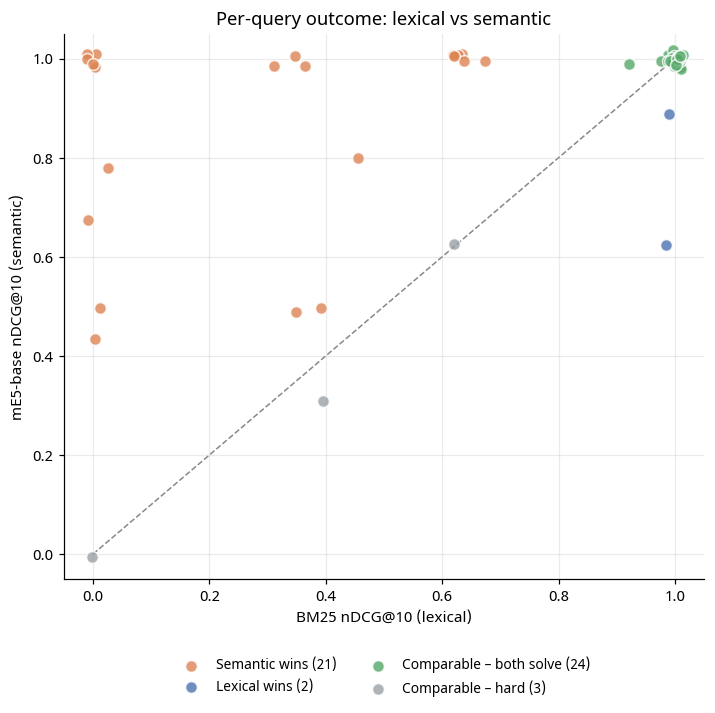

Margin rule: |nDCG@10 difference| >= 0.1.   {'Semantic wins': 21, 'Lexical wins': 2, 'Comparable – both solve': 24, 'Comparable – hard': 3}


In [16]:
# Per-query outcome: BM25 (lexical) vs the best encoder (semantic). A difference counts only if it is >= 0.10 nDCG@10.
SEM, THRESH = DENSE_BEST, 0.10
n_lex, n_sem = PQ["BM25"]["ndcg@10"], PQ[SEM]["ndcg@10"]
diff = n_sem - n_lex
CATS = ["Semantic wins", "Lexical wins", "Comparable – both solve", "Comparable – hard"]
category = pd.Series(np.select([diff >= THRESH, diff <= -THRESH, (n_lex >= 0.9) & (n_sem >= 0.9)],
                               CATS[:3], default=CATS[3]), index=diff.index)
CAT_COLOR = dict(zip(CATS, [C_DENSE, C_LEX, C_HYB, C_BASE]))
counts = category.value_counts().reindex(CATS).fillna(0).astype(int)

rng = np.random.default_rng(SEED)
jx, jy = rng.normal(0, 0.012, len(n_lex)), rng.normal(0, 0.012, len(n_sem))
fig, ax = plt.subplots(figsize=(6.6, 6.6))
ax.plot([0, 1], [0, 1], color="#888", ls="--", lw=1, zorder=1)
for c in CATS:
    mask = (category == c).values
    ax.scatter(n_lex.values[mask] + jx[mask], n_sem.values[mask] + jy[mask], s=60, alpha=0.8, color=CAT_COLOR[c],
               edgecolor="white", label=f"{c} ({counts[c]})", zorder=2)
ax.set_xlabel("BM25 nDCG@10 (lexical)"); ax.set_ylabel(f"{SEM} nDCG@10 (semantic)")
ax.set_title("Per-query outcome: lexical vs semantic"); ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.05, 1.05)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=9, frameon=False)
plt.tight_layout(); plt.savefig("results/fig_lexical_vs_semantic.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"Margin rule: |nDCG@10 difference| >= {THRESH}.  ", counts.to_dict())

### Observation 2 — Patterns across queries
- **16 of the 50 queries are solved perfectly by every method.** The methods differ on the harder queries, where the keyword columns show many more low scores than the embedding columns.
- Counting only differences of at least 0.10 nDCG@10, **embeddings win on 21 queries and BM25 on only 2.** In 24 queries both are comparable and good, and in 3 both struggle.
- Section 10 reads examples to explain why.

## 9 · Are the differences real?
A method can look better on 50 queries just by luck. To check, we use a **paired bootstrap**: compare two methods on the same queries, resample the 50 queries 2,000 times and recompute the difference each time. If the 95% range of the difference does not include 0, we call the difference **significant** (unlikely to be luck).

We make 8 comparisons, so one of them could look significant by chance. **Bonferroni** is a stricter check that allows for this; a result that "survives Bonferroni" is very likely real.

In [17]:
def paired_bootstrap(a, b, B=B, seed=SEED, n_tests=8):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(a), (B, len(a)))
    d = (a[idx] - b[idx]).mean(axis=1)
    lo, hi = np.percentile(d, [2.5, 97.5])
    blo, bhi = np.percentile(d, [100 * 0.025 / n_tests, 100 * (1 - 0.025 / n_tests)])
    p = max(1.0 / B, min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean())))
    return (a - b).mean(), lo, hi, p, (blo > 0 or bhi < 0)

pairs = [("TF-IDF (fixed)", "TF-IDF (midterm)"),  # does fixing the tokenizer matter?
         ("BM25", "TF-IDF (fixed)"),               # BM25 vs TF-IDF
         ("MiniLM", "BM25"),                       # semantic vs lexical (research question)
         ("mE5-base", "BM25"),
         ("mE5-base", "MiniLM"),                   # does a stronger encoder help?
         ("Hybrid RRF", "mE5-base"),               # does fusion help the best encoder?
         ("Hybrid RRF", "MiniLM"),
         ("Hybrid RRF", "BM25")]
rows = []
for a, b in pairs:
    d, lo, hi, p, sig_b = paired_bootstrap(PQ[a]["ndcg@10"].values, PQ[b]["ndcg@10"].values, n_tests=len(pairs))
    rows.append({"A": a, "B": b, "mean diff (A−B)": d, "95% CI low": lo, "95% CI high": hi, "p (approx.)": p,
                 "significant (95%)": "yes" if (lo > 0 or hi < 0) else "no",
                 "survives Bonferroni": "yes" if sig_b else "no"})
paired = pd.DataFrame(rows)
paired.round(4).to_csv("results/paired_tests.csv", index=False)
fmt = {c: "{:+.3f}" for c in ["mean diff (A−B)", "95% CI low", "95% CI high"]}
fmt["p (approx.)"] = lambda x: "< 0.001" if x < 0.001 else f"{x:.3f}"
paired.style.format(fmt).hide(axis="index")

A,B,mean diff (A−B),95% CI low,95% CI high,p (approx.),significant (95%),survives Bonferroni
TF-IDF (fixed),TF-IDF (midterm),+0.043,-0.044,+0.136,0.357,no,no
BM25,TF-IDF (fixed),-0.034,-0.071,+0.004,0.081,no,no
MiniLM,BM25,+0.187,+0.071,+0.305,0.001,yes,yes
mE5-base,BM25,+0.235,+0.139,+0.332,< 0.001,yes,yes
mE5-base,MiniLM,+0.048,-0.015,+0.110,0.140,no,no
Hybrid RRF,mE5-base,-0.118,-0.192,-0.050,< 0.001,yes,yes
Hybrid RRF,MiniLM,-0.070,-0.163,+0.028,0.152,no,no
Hybrid RRF,BM25,+0.117,+0.076,+0.160,< 0.001,yes,yes


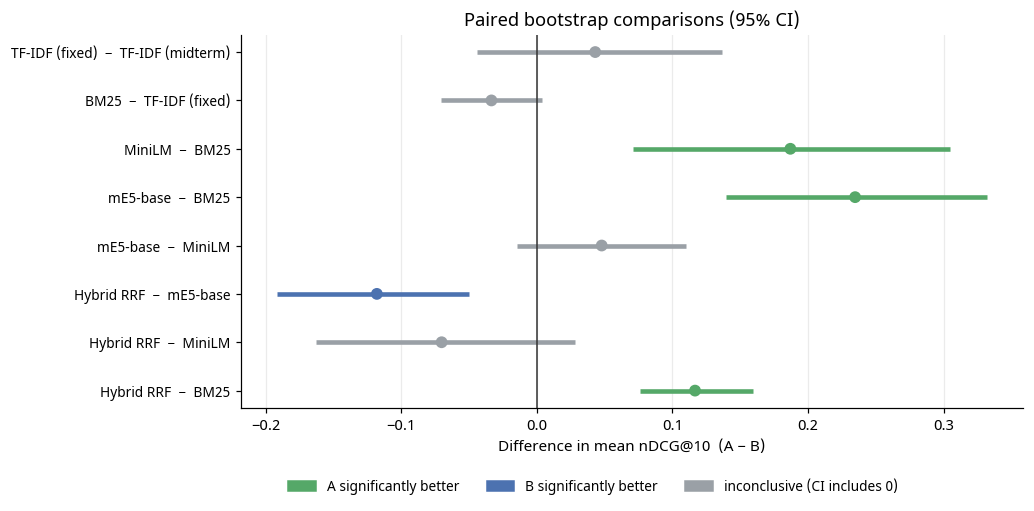

In [18]:
from matplotlib.patches import Patch
fig, ax = plt.subplots(figsize=(9.5, 4.8))
labels = [f"{a}  −  {b}" for a, b in zip(paired["A"], paired["B"])][::-1]
d, lo, hi = paired["mean diff (A−B)"][::-1].values, paired["95% CI low"][::-1].values, paired["95% CI high"][::-1].values
colors = [C_HYB if l > 0 else (C_LEX if h < 0 else C_BASE) for l, h in zip(lo, hi)]
ax.hlines(range(len(d)), lo, hi, color=colors, lw=3)
ax.scatter(d, range(len(d)), color=colors, zorder=3, s=45)
ax.axvline(0, color="#333", lw=1)
ax.set_yticks(range(len(d))); ax.set_yticklabels(labels, fontsize=9)
ax.set_xlabel("Difference in mean nDCG@10  (A − B)")
ax.set_title("Paired bootstrap comparisons (95% CI)"); ax.grid(axis="y", alpha=0)
ax.legend(handles=[Patch(color=C_HYB, label="A significantly better"), Patch(color=C_LEX, label="B significantly better"),
                   Patch(color=C_BASE, label="inconclusive (CI includes 0)")],
          loc="upper center", bbox_to_anchor=(0.45, -0.16), ncol=3, frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig("results/fig_paired_tests.png", dpi=150, bbox_inches="tight"); plt.show()

### Observation 3 — What the statistics support
**Significant, and survive Bonferroni**
- **mE5-base beats BM25:** +0.235 nDCG@10 (95% range 0.139 to 0.332).
- **MiniLM beats BM25:** +0.187 (0.071 to 0.305). So the advantage is not specific to one embedding model.
- **The hybrid is worse than mE5-base alone:** −0.118 (−0.192 to −0.050). Per query, it is worse on 13 queries, similar on 34 and better on only 3.
- **The hybrid is better than BM25 alone:** +0.117 (0.076 to 0.160). Combining helps a weak method but not a strong one.

**Not significant (the range includes 0)**
- Fixing the tokenizer: TF-IDF goes from 0.649 to 0.692, but the difference (+0.043, range −0.044 to +0.136) could be luck.
- BM25 vs fixed TF-IDF: −0.034 (−0.071 to +0.004).
- mE5-base vs MiniLM: +0.048 (−0.015 to +0.110). We cannot say the larger model is better.
- Hybrid vs MiniLM: −0.070 (−0.163 to +0.028).

**Why does combining hurt?** This is our hypothesis, supported by the table in Section 10. The hybrid gives both methods an equal vote. In 9 of 50 queries mE5 ranks a relevant document first but the hybrid does not; in the eight most extreme of these (the table in Section 10), BM25 ranks that document between 7th and 68th, which pulls the combined rank down.

## 10 · Reading the errors
Scores show *how much* the methods differ; examples show *why*. We compare BM25 (keyword) with mE5 (embedding) query by query. A method "wins" only if its nDCG@10 is higher by at least 0.10; otherwise the query is "comparable" (both solve it, or both find it hard). In the examples below, ✔ marks a relevant document, and "rank" is the position of the first relevant one.

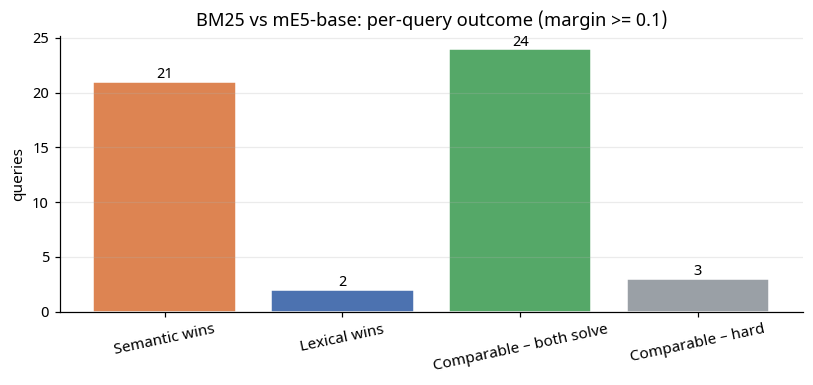

Hybrid vs mE5-base, per query (margin 0.1):  hybrid worse on 13, similar on 34, better on 3 of 50 queries.


In [19]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.bar(counts.index, counts.values, color=[CAT_COLOR[c] for c in counts.index], edgecolor="white")
for i, v in enumerate(counts.values): ax.text(i, v + 0.3, str(v), ha="center", fontweight="bold")
ax.set_ylabel("queries"); ax.set_title(f"BM25 vs {SEM}: per-query outcome (margin >= {THRESH})"); ax.grid(axis="x", alpha=0)
plt.xticks(rotation=12); plt.tight_layout(); plt.savefig("results/fig_error_categories.png", dpi=150, bbox_inches="tight"); plt.show()

# Does fusion help query by query? Compare the hybrid with the best encoder alone.
h = PQ["Hybrid RRF"]["ndcg@10"] - PQ[SEM]["ndcg@10"]
print(f"Hybrid vs {SEM}, per query (margin {THRESH}):  hybrid worse on {int((h <= -THRESH).sum())}, "
      f"similar on {int((h.abs() < THRESH).sum())}, better on {int((h >= THRESH).sum())} of {len(h)} queries.")

In [20]:
def show_case(qid, methods=("BM25", SEM, "Hybrid RRF"), k=3):
    qt, rel = QTEXTS[QIDS.index(qid)], QRELS[qid]
    print("═" * 100)
    print(f"QUERY [{qid}]: {qt}")
    print("RELEVANT:")
    for d in rel: print("   •", text_by_id[d])
    for m in methods:
        r = RANKINGS[m][qid]
        first = next((i + 1 for i, d in enumerate(r) if d in rel), None)
        print(f"  [{m}]  first relevant at rank: {first if first else '>100'}")
        for d in r[:k]:
            print(f"     {'✔' if d in rel else '✗'} {text_by_id[d]}")

print("######## SEMANTIC WINS (largest margins) ########")
for q in diff[category == "Semantic wins"].sort_values(ascending=False).index[:3]: show_case(q)

######## SEMANTIC WINS (largest margins) ########
════════════════════════════════════════════════════════════════════════════════════════════════════
QUERY [362950]: मैं अपने कैरियर के हित का निर्धारण कैसे करूं?
RELEVANT:
   • मैं अपने करियर के हितों का पता कैसे लगा सकता हूँ?
   • मुझे अपने करियर के हितों का पता कैसे लगाना चाहिए?
  [BM25]  first relevant at rank: 68
     ✗ मैं आईटी कैरियर कैसे सेट करूं?
     ✗ मैं अपने शौक को कैरियर में कैसे बदलूं?
     ✗ मुझे अपने कैरियर का लक्ष्य कैसे तय करना चाहिए?
  [mE5-base]  first relevant at rank: 1
     ✔ मुझे अपने करियर के हितों का पता कैसे लगाना चाहिए?
     ✔ मैं अपने करियर के हितों का पता कैसे लगा सकता हूँ?
     ✗ मुझे अपने कैरियर का लक्ष्य कैसे तय करना चाहिए?
  [Hybrid RRF]  first relevant at rank: 7
     ✗ मुझे अपने कैरियर का लक्ष्य कैसे तय करना चाहिए?
     ✗ मैं अपने शौक को कैरियर में कैसे बदलूं?
     ✗ मैं आईटी कैरियर कैसे सेट करूं?
════════════════════════════════════════════════════════════════════════════════════════════════════
QUE

In [21]:
print("######## LEXICAL WINS (margin ≥ 0.10; shows all, up to 3) ########")
lw = diff[category == "Lexical wins"].sort_values().index[:3]
if len(lw) == 0: print("(none)")
for q in lw: show_case(q)

######## LEXICAL WINS (margin ≥ 0.10; shows all, up to 3) ########
════════════════════════════════════════════════════════════════════════════════════════════════════
QUERY [315712]: इसका इलाज कैसे किया जा सकता है?
RELEVANT:
   • यदि नहीं, तो इसका इलाज कैसे किया जा सकता है?
  [BM25]  first relevant at rank: 1
     ✔ यदि नहीं, तो इसका इलाज कैसे किया जा सकता है?
     ✗ मौखिक हर्पेस कितना आम है? इसका इलाज कैसे किया जा सकता है?
     ✗ बॉर्डरलाइन पर्सनैलिटी डिसऑर्डर क्या है और इसका इलाज कैसे किया जा सकता है?
  [mE5-base]  first relevant at rank: 2
     ✗ गठिया का इलाज कैसे किया जा सकता है?
     ✔ यदि नहीं, तो इसका इलाज कैसे किया जा सकता है?
     ✗ अम्लता का इलाज कैसे किया जा सकता है?
  [Hybrid RRF]  first relevant at rank: 1
     ✔ यदि नहीं, तो इसका इलाज कैसे किया जा सकता है?
     ✗ गठिया का इलाज कैसे किया जा सकता है?
     ✗ पीटीएसडी का इलाज कैसे किया जा सकता है?
════════════════════════════════════════════════════════════════════════════════════════════════════
QUERY [14755]: कितनी बार हस

In [22]:
print("######## HARD QUERIES (both methods within 0.10 and below 0.9; hardest first, up to 3) ########")
print("(The first two look like translation inconsistencies: the query and its labelled match use different Hindi words for the same idea.)")
hard = category[category == "Comparable – hard"].index
hard = sorted(hard, key=lambda q: max(n_lex[q], n_sem[q]))[:3]
if len(hard) == 0: print("(none)")
for q in hard: show_case(q)

######## HARD QUERIES (both methods within 0.10 and below 0.9; hardest first, up to 3) ########
════════════════════════════════════════════════════════════════════════════════════════════════════
QUERY [511196]: बाल सहायता कैसे अन्यायपूर्ण हो सकती है?
RELEVANT:
   • बच्चों के समर्थन के कुछ उदाहरण क्या हैं?
  [BM25]  first relevant at rank: >100
     ✗ बाल सहायता की आपकी समीक्षा क्या है?
     ✗ गर्भवती हो सकती है?
     ✗ शेयर की कीमत कैसे स्थिर हो सकती है?
  [mE5-base]  first relevant at rank: 14
     ✗ बाल श्रम में क्या बुराई है यदि बच्चे का अच्छा व्यवहार किया जाए?
     ✗ बाल सहायता की आपकी समीक्षा क्या है?
     ✗ सामाजिक न्याय के संदर्भ में अन्यायपूर्ण और अन्यायपूर्ण के बीच क्या अंतर है?
  [Hybrid RRF]  first relevant at rank: 43
     ✗ बाल सहायता की आपकी समीक्षा क्या है?
     ✗ जीवन किस प्रकार अन्यायपूर्ण है?
     ✗ सामाजिक न्याय के संदर्भ में अन्यायपूर्ण और अन्यायपूर्ण के बीच क्या अंतर है?
═════════════════════════════════════════════════════════════════════════════════════════════

In [24]:
print("######## WHY FUSION HURT: relevant doc ranked high by the encoder, low by BM25 ########")
rank_of = lambda m, q: next((i + 1 for i, d in enumerate(RANKINGS[m][q]) if d in QRELS[q]), 101)
cand = pd.DataFrame({"BM25 rank": {q: rank_of("BM25", q) for q in QIDS},
                     f"{SEM} rank": {q: rank_of(SEM, q) for q in QIDS},
                     "Hybrid rank": {q: rank_of("Hybrid RRF", q) for q in QIDS}})
hurt = cand[(cand[f"{SEM} rank"] == 1) & (cand["Hybrid rank"] > 1)].sort_values("BM25 rank", ascending=False)
print(f"Queries where the encoder ranks a relevant doc FIRST but the hybrid does not: {len(hurt)}/{len(QIDS)}")
print("(rank 101 = not in top 100)")
hurt.head(8)

######## WHY FUSION HURT: relevant doc ranked high by the encoder, low by BM25 ########
Queries where the encoder ranks a relevant doc FIRST but the hybrid does not: 9/50
(rank 101 = not in top 100)


,BM25 rank,mE5-base rank,Hybrid rank
362950,68,1,7
13800,37,1,10
215681,37,1,8
127880,21,1,7
155873,15,1,4
344845,11,1,4
167969,9,1,2
415592,7,1,3


### Observation 4 — When does each method work?
- **Embeddings win on paraphrases and spelling or wording differences.** In the career-interests query the relevant document is at rank 68 for BM25 but rank 1 for mE5. For the "advice about life" query the ranks are 11 vs 1, and for the "रमा / राम" query 15 vs 1. The meaning is the same but the words differ, which keyword matching cannot handle.
- **Keyword search wins rarely (2 of 50 queries).** The clearest example is the generic query *"इसका इलाज कैसे किया जा सकता है?"* ("how can this be treated?"): BM25 ranks the relevant document first, while mE5 ranks questions about specific diseases above it.
- **The hard queries are partly a data problem.** Two of the three look like translation inconsistencies of the same English question (*दानवीकरण* vs *नोटबंदी*, and *बाल सहायता* vs *बच्चों के समर्थन*). The third (*"मैं धन कैसे जुटाऊं?"*) is so vague that many similar questions fit. No method can score well on such cases.
- **Why combining hurt** is visible in the last table of this section: mE5 ranks the relevant document first, BM25 ranks it much lower, and the combination lands in between.

## 11 · Did our midterm observations hold up?
At the midterm we said TF-IDF did better on Q1 and embeddings did better on Q8. Here are those two queries again, through all methods.

In [25]:
def compare(query, methods=tuple(NAMES.values()), k=3):
    excl = text2idx.get(clean_text(query), [])
    print("═" * 100); print("QUERY:", query)
    for name, key in NAMES.items():
        if key not in methods: continue
        print(f"  [{name}]")
        for _, txt, sc in search(query, key, k, exclude=excl):
            print(f"      {sc:.3f}  {txt}")

for label in ("Q1 (definition)", "Q8 (abstract)"):
    compare(representative_queries[label])

════════════════════════════════════════════════════════════════════════════════════════════════════
QUERY: स्क्रम मास्टर क्या है?
  [TF-IDF (midterm)]
      0.907  स्क्रम मास्टर की भूमिकाएं और जिम्मेदारियां क्या हैं?
      0.770  ट्विटर (कंपनी) के लिए डोनाल्ड ट्रम्प का मौद्रिक मूल्य क्या है?
      0.717  मास्टर.जीजी क्या है?
  [TF-IDF (fixed)]
      0.627  स्क्रम मास्टर की भूमिकाएं और जिम्मेदारियां क्या हैं?
      0.596  एजाइल स्क्रम मास्टर प्रमाणन के दायरे क्या हैं?
      0.460  क्या स्क्रम एलायंस सीएसटी (प्रमाणित स्क्रम प्रशिक्षकों) को अन्य प्रशिक्षणों जैसे कि पीएमआई-एसीपी, एक्सिन स्क्रम, एसएएफई आदि लेने की अनुमति देता है?
  [BM25]
      15.442  स्क्रम मास्टर की भूमिकाएं और जिम्मेदारियां क्या हैं?
      15.442  एजाइल स्क्रम मास्टर प्रमाणन के दायरे क्या हैं?
      11.539  मास्टर.जीजी क्या है?
  [MiniLM]
      0.910  मास्टर.जीजी क्या है?
      0.830  बढ़ई: एक मास्टर बढ़ई की परिभाषा क्या है?
      0.750  स्क्रम मास्टर की भूमिकाएं और जिम्मेदारियां क्या हैं?
  [mE5-base]
      0.874  स्क

### Observation 5 — Midterm claims revisited
- **Q1 (*स्क्रम मास्टर क्या है?*).** At the midterm, MiniLM missed the Scrum Master question, and we concluded that keyword matching was better here. Now fixed TF-IDF, BM25 **and mE5-base** all rank it first; only MiniLM ranks it third. So the midterm result was specific to MiniLM, not a general weakness of embeddings.
- **Q8 (*समय इतनी तेजी से…*).** At the midterm, TF-IDF returned a weakly related question while MiniLM found a paraphrase. Now BM25 and mE5-base return the same top result (*उम्र बढ़ने के साथ समय तेजी से क्यों बीतता है?*), while TF-IDF (fixed) still returns the weaker one. The difference came from TF-IDF's weighting, not from keyword search in general.
- Both midterm observations were real but drawn from one query and one model. The 50-query evaluation (Sections 7–9) is the reliable evidence.

## 12 · Save results
Saves the tables and charts to the `results/` folder for the report and the GitHub README.

In [26]:
M.to_csv("results/per_query_ndcg10.csv")
category.rename("category").to_csv("results/per_query_category.csv")
json.dump({"hybrid_components": HYBRID_COMPONENTS, "rrf_k": RRF_K, "dense_best": DENSE_BEST, "margin": THRESH,
           "models": {k: v["name"] for k, v in DENSE.items()}, "seed": SEED}, open("results/config.json", "w"), indent=2)

best = summary["nDCG@10"].idxmax()
print(f"Best method by nDCG@10: {best} ({summary.loc[best, 'nDCG@10']:.3f})")
print(f"Midterm TF-IDF -> fixed TF-IDF: {summary.loc['TF-IDF (midterm)', 'nDCG@10']:.3f} -> {summary.loc['TF-IDF (fixed)', 'nDCG@10']:.3f}")
print("Files in results/:", sorted(os.listdir("results")))
# In Colab, download everything:  !zip -qr results.zip results cache/*.npy  ->  then files.download("results.zip")

Best method by nDCG@10: mE5-base (0.893)
Midterm TF-IDF -> fixed TF-IDF: 0.649 -> 0.692
Files in results/: ['config.json', 'fig_data_overview.png', 'fig_error_categories.png', 'fig_lexical_vs_semantic.png', 'fig_main_results.png', 'fig_paired_tests.png', 'fig_per_query_heatmap.png', 'fig_tokenizer_audit.png', 'paired_tests.csv', 'per_query_category.csv', 'per_query_ndcg10.csv', 'summary.csv']


## 13 · Relation to the reference papers

| Paper | What it does | What we used | What we did not do |
|---|---|---|---|
| **Hindi-BEIR / NLLB-E5** (Acharya et al., NAACL 2025) | Builds a benchmark of 15 Hindi retrieval datasets and a new multilingual retrieval model, NLLB-E5 | Its evaluation method (nDCG@10), its baselines (BM25 and multilingual E5), and its list of Hindi-specific challenges (script, word forms, ambiguity) | We did not train NLLB-E5 |
| **IndicIRSuite** (Haq et al., ACL 2024) | Translates a large English search dataset into 11 Indian languages and trains Indic-ColBERT models on it | Its warning that machine-translated Indian-language data contains translation noise, which we saw in Section 10 | We did not use Indic-ColBERT |

**Do our results agree with the papers?** In direction, yes. Hindi-BEIR reports multilingual E5 above BM25 on average (nDCG@10 44.37 vs 35.65 over its datasets), though BM25 still wins on a few datasets. IndicIRSuite reports Indic-ColBERT above BM25 on MIRACL Hindi (0.483 vs 0.458). The absolute numbers cannot be compared with ours because the datasets differ.


## 14 · Interactive prototype
A small web interface on top of the retrieval engine from Section 3, so the system can be tried on any Hindi question. It has two tabs:

- **Search:** type a Hindi question and see the top results of the chosen methods side by side. For the 50 evaluation queries, a ✔ marks the questions labelled as relevant.
- **Query explorer:** pick any evaluation query to see its relevant question(s), where each method ranked them, and the top 3 results of every method. These ranks come from the evaluation run in Section 7.

The interface searches only the 5,046 project questions. Run the three cells below in order (they need the models and results already loaded in this session), then open the link that the last cell prints.


In [ ]:
!pip install -q gradio

In [ ]:

import html, inspect
import gradio as gr

DEMO_METHODS   = list(NAMES.keys())                                   # same six methods as the evaluation
DEFAULT_METHODS = ["TF-IDF (fixed)", "BM25", "mE5-base", "Hybrid RRF"]
qt2qid = {clean_text(t): q for t, q in zip(QTEXTS, QIDS)}            # evaluation queries, found by their text

STYLE = """<style>
.hs-grid{display:grid;grid-template-columns:repeat(auto-fit,minmax(250px,1fr));gap:12px;margin-top:8px}
.hs-col{border:1px solid rgba(128,128,128,.45);border-radius:4px;padding:8px 12px;min-width:0}
.hs-col h4{margin:0 0 6px 0;padding-bottom:6px;border-bottom:1px solid rgba(128,128,128,.45);font-size:.95rem}
.hs-row{display:flex;gap:8px;padding:5px 0;border-bottom:1px dotted rgba(128,128,128,.35);font-size:.95rem;line-height:1.4}
.hs-row:last-child{border-bottom:none}
.hs-rank{opacity:.6;min-width:1.3em}
.hs-text{flex:1}
.hs-score{opacity:.55;font-size:.8rem;white-space:nowrap}
.hs-hit .hs-text{font-weight:600}
.hs-note{opacity:.8;font-size:.9rem;margin:6px 0}
.hs-table{border-collapse:collapse;width:100%;font-size:.95rem;margin:8px 0;border:none!important}
.hs-table tr,.hs-table thead,.hs-table tbody{border:none!important;box-shadow:none!important}
.hs-table th,.hs-table td{border:none!important;border-bottom:1px solid rgba(128,128,128,.4)!important;padding:5px 8px;text-align:left}
</style>"""

def _column(title, rows, relevant=None):
    """One method's result list. rows = [(doc_id, text, score_or_None)]."""
    parts = ['<div class="hs-col"><h4>' + html.escape(title) + '</h4>']
    for rank, (did, text, score) in enumerate(rows, 1):
        hit = relevant is not None and did in relevant
        cls = "hs-row hs-hit" if hit else "hs-row"
        mark = "✔ " if hit else ""
        sc = "" if score is None else '<span class="hs-score">' + f"{score:.3f}" + '</span>'
        parts.append('<div class="' + cls + '"><span class="hs-rank">' + str(rank) + '</span>'
                     '<span class="hs-text">' + mark + html.escape(text) + '</span>' + sc + '</div>')
    parts.append('</div>')
    return "".join(parts)

def run_search(query, methods, k):
    q = clean_text(query)
    if not q:
        return STYLE + '<div class="hs-note">Type a Hindi question above.</div>'
    if not methods:
        return STYLE + '<div class="hs-note">Select at least one method.</div>'
    qid = qt2qid.get(q)
    excl = SELF_EXCL[qid] if qid else []
    relevant = set(QRELS[qid]) if qid else None
    cols = [_column(name, search(q, NAMES[name], int(k), exclude=excl), relevant) for name in methods]
    if qid:
        note = (f"This is evaluation query {qid}. A ✔ marks a question labelled as relevant. "
                "An identical copy of the query is left out, as in the evaluation.")
    else:
        note = ("Free-text query, so no labels are available and results are not marked. "
                "Scores are not comparable across methods (cosine, TF-IDF, BM25 and RRF scores differ in scale).")
    return STYLE + '<div class="hs-note">' + html.escape(note) + '</div><div class="hs-grid">' + "".join(cols) + '</div>'

CAT_ORDER = ["All"] + list(CATS)                                      # outcome categories from Section 8

def _choices(cat):
    ids = [q for q in QIDS if cat == "All" or category[q] == cat]
    return [f"{q} · {QTEXTS[QIDS.index(q)][:70]}" for q in ids]

def explore(choice):
    if not choice:
        return STYLE + '<div class="hs-note">Pick an evaluation query.</div>'
    qid = choice.split(" · ")[0]
    qt, rel = QTEXTS[QIDS.index(qid)], QRELS[qid]
    parts = [STYLE,
             '<div class="hs-note"><b>Query ' + html.escape(qid) + '</b> · outcome: <b>' + html.escape(str(category[qid])) + '</b></div>',
             '<div style="font-size:1.1rem;margin:4px 0 10px 0">' + html.escape(qt) + '</div>',
             '<div class="hs-note"><b>Labelled relevant question(s)</b></div>']
    for d in rel:
        parts.append('<div class="hs-row"><span class="hs-text">' + html.escape(text_by_id[d]) + '</span></div>')
    trs = []
    for name in NAMES:
        ranked = RANKINGS[name][qid]
        first = next((i + 1 for i, d in enumerate(ranked) if d in rel), None)
        trs.append("<tr><td>" + html.escape(name) + "</td><td>" + (str(first) if first else "&gt;100") + "</td><td>"
                   + f"{PQ[name].loc[qid, 'ndcg@10']:.2f}" + "</td></tr>")
    parts.append('<table class="hs-table"><tr><th>Method</th><th>Rank of first relevant</th><th>nDCG@10</th></tr>' + "".join(trs) + '</table>')
    parts.append('<div class="hs-note"><b>Top 3 results per method</b> (✔ = labelled relevant)</div><div class="hs-grid">')
    for name in NAMES:
        rows = [(d, text_by_id[d], None) for d in RANKINGS[name][qid][:3]]
        parts.append(_column(name, rows, set(rel)))
    parts.append('</div>')
    return "".join(parts)

# example queries: taken from the dataset itself, plus one free-text paraphrase that is not in it
def _q(qid):
    return QTEXTS[QIDS.index(qid)] if qid in QIDS else None
EXAMPLES = [t for t in [_q("362950"), _q("155873"), _q("315712"),
                        representative_queries["Q1 (definition)"], representative_queries["Q8 (abstract)"]] if t]
EXAMPLES.append("दिन इतनी जल्दी क्यों बीत जाते हैं?")                 # free text (not in the dataset)

THEME = gr.themes.Base(primary_hue="slate", neutral_hue="slate")
_theme_in_launch = "theme" in inspect.signature(gr.Blocks.launch).parameters   # Gradio 6 moved theme to launch()

with gr.Blocks(title="Hindi question search", **({} if _theme_in_launch else {"theme": THEME})) as demo:
    gr.Markdown("## Hindi question search: keyword vs semantic retrieval\n"
                "Searches the 5,046 Hindi questions of the project dataset with the methods compared in this notebook.")
    with gr.Tabs():
        with gr.Tab("Search"):
            query = gr.Textbox(label="Hindi question", placeholder="उदाहरण: दिन इतनी जल्दी क्यों बीत जाते हैं?", lines=1)
            with gr.Row():
                methods = gr.CheckboxGroup(DEMO_METHODS, value=DEFAULT_METHODS, label="Methods")
                topk = gr.Slider(3, 10, value=5, step=1, label="Results per method")
            go = gr.Button("Search", variant="primary")
            out = gr.HTML()
            gr.Examples(examples=[[t] for t in EXAMPLES], inputs=[query], label="Examples (click one, then press Search)")
            go.click(run_search, [query, methods, topk], out)
            query.submit(run_search, [query, methods, topk], out)
        with gr.Tab("Query explorer"):
            cat = gr.Radio(CAT_ORDER, value="All", label="Show evaluation queries by outcome (BM25 vs the best embedding model)")
            pick = gr.Dropdown(_choices("All"), label="Evaluation query")
            view = gr.HTML()
            cat.change(lambda c: gr.update(choices=_choices(c), value=None), cat, pick)
            pick.change(explore, pick, view)
print("Interface built. Run the next cell to launch it.")


In [ ]:

demo.launch(share=True, debug=False, **({"theme": THEME} if _theme_in_launch else {}))


## 15 · Conclusions

**Question.** Do sentence embeddings find better matches than keyword search for Hindi questions?

**Answer: yes.** mE5-base scores nDCG@10 = 0.893, against 0.692 for the best TF-IDF and 0.658 for BM25. Both embedding models beat BM25 by more than luck can explain (mE5 +0.235, MiniLM +0.187), even after the Bonferroni check and without the 3 easy queries.

### What we found

| # | Finding | Evidence | Confidence |
|---|---|---|---|
| 1 | Embeddings beat keyword search | +0.19 to +0.24 nDCG@10; embeddings win on 21 queries, keyword search on 2 | High |
| 2 | The gain comes from paraphrases and wording differences | Relevant documents at BM25 ranks 11 to 68 but at embedding rank 1 | Medium (from reading examples) |
| 3 | Combining BM25 with mE5 (equal weights) hurts | −0.118 vs mE5 alone; worse on 13 queries, better on 3 | High, for this combination method only |
| 4 | The combination still beats BM25 alone | +0.117 | High |
| 5 | The midterm tokenizer broke Hindi words | 0% of words with vowel signs kept intact; they are 90% of the corpus | High |
| 6 | That bug lowered TF-IDF's ranking quality | +0.043 after the fix, but could be luck | Not shown |
| 7 | mE5-base is better than MiniLM | +0.048, but could be luck | Not shown |
| 8 | BM25 is stronger than TF-IDF (what we expected) | Not seen: BM25 is 0.034 lower, but this could be luck | Not shown |
| 9 | Some errors come from the data, not the methods | Translation inconsistencies and a very vague query | Medium (3 cases) |

### Explanation
- **Why embeddings win.** Many Quora questions are the same question worded differently. Embeddings compare meaning; TF-IDF and BM25 can only compare shared words.
- **Why combining hurt (hypothesis).** When one method is much better, giving the weaker one an equal vote pulls good results down. Weighted voting might help, but we did not try it.
- **Why the tokenizer fix did not show a clear gain (hypothesis).** The broken tokenizer still kept some useful fragments, and 50 queries may be too few to detect a small gain. We did not test this.

### Recommendation
For short Hindi questions, use a multilingual embedding model alone and skip the simple combination. MiniLM is smaller and, on our data, not clearly worse than mE5-base, so it is a reasonable choice when speed matters.

### What we cannot conclude
- That the results hold for long documents, other domains or other Indian languages.
- That combining keyword and embedding search can never help (we tried only one way of combining).
- That mE5-base is better than MiniLM, or that the tokenizer fix does not matter.

### Limitations
- **Small test:** 50 queries and one dataset of short questions.
- **Machine-translated data:** some query–document pairs are inconsistent (Section 10).
- **Incomplete labels:** only about 1.4 relevant documents per query are labelled. A good match that was not labelled counts as a mistake, which lowers every method's score.
- **Small corpus:** with only 5,046 questions, absolute scores are higher than on a full-size search and cannot be compared with published numbers. Only the comparison between methods is meaningful.
- **Choices made on the test queries:** the partner for the hybrid was chosen on the same 50 queries, and no combination weights were tuned.
- We did not fine-tune any model and compared only two embedding models.

### Future work
Weighted combination tuned on separate queries; more datasets with longer documents; reproducing NLLB-E5; searching Hindi documents with English queries.

### Corrections to the midterm
Our midterm TF-IDF baseline broke Hindi words into fragments (Section 5), and two midterm observations (Q1, Q8) applied only to one model or to TF-IDF's weighting (Section 11).

### Acknowledgements
We used an AI assistant (Anthropic's Claude) to help draft and review the code and text. We ran all experiments ourselves and checked the results. Libraries: scikit-learn, rank_bm25, sentence-transformers, ranx, pandas, matplotlib. Dataset: `carlfeynman/Bharat_NanoQuoraRetrieval_hi` on Hugging Face.

### References
- Haq et al., *IndicIRSuite: Multilingual Dataset and Neural Information Models for Indian Languages*, ACL 2024.
- Acharya et al., *Benchmarking and Building Zero-Shot Hindi Retrieval Model with Hindi-BEIR and NLLB-E5*, NAACL 2025.
- Thakur et al., *BEIR: A Heterogenous Benchmark for Zero-shot Evaluation of Information Retrieval Models*, 2021.
- Wang et al., *Multilingual E5 Text Embeddings: A Technical Report*, 2024.
- Reimers & Gurevych, *Sentence-BERT*, EMNLP 2019.